# Step 3 — Baseline (TF-IDF + Logistic Regression) and SimpleRNN
**Inputs needed (Add Input → Notebook Output):** the outputs of Step 1 (`splits/`) AND Step 2 (`processed/`).

**What we do here**
1. Train a simple *non-deep* baseline. Every neural model must beat it, otherwise deep learning wasn't worth it.
2. Define a reusable evaluation function (Accuracy, Precision, Recall, F1, Confusion Matrix) — all later models use the same one.
3. Build and train the **SimpleRNN** from scratch.

## 3.1 Setup & load

In [4]:
import os, glob, json, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, classification_report, confusion_matrix

SEED = 42
keras.utils.set_random_seed(SEED)

QUICK = False   # set True to smoke-test everything on a tiny subset (~1 min), then back to False

def find(pattern):
    hits = glob.glob(pattern) + glob.glob('/kaggle/input/**/' + pattern, recursive=True) + glob.glob('/kaggle/working/' + pattern)
    assert hits, f'Could not find {pattern}. Add the Step 1 AND Step 2 notebook outputs as Input.'
    return hits[0]

data = np.load(find('processed/data.npz'))
X_train, y_train, X_val, y_val, X_test, y_test = [data[k] for k in ['X_train','y_train','X_val','y_val','X_test','y_test']]
meta = json.load(open(find('processed/meta.json')))
tok  = json.load(open(find('processed/tokenizer.json')))
label2id = meta['label2id']; class_weight = {int(k): v for k, v in meta['class_weight'].items()}
class_names = [c for c, _ in sorted(label2id.items(), key=lambda x: x[1])]
VOCAB_SIZE, MAX_LEN = tok['vocab_size'], tok['max_len']

train_text = pd.read_csv(find('splits/train.csv'))['narrative']
val_text   = pd.read_csv(find('splits/val.csv'))['narrative']
test_text  = pd.read_csv(find('splits/test.csv'))['narrative']

if QUICK:
    X_train, y_train, train_text = X_train[:3000], y_train[:3000], train_text[:3000]
    X_val, y_val = X_val[:1000], y_val[:1000]
    X_test, y_test, test_text = X_test[:1000], y_test[:1000], test_text[:1000]

os.makedirs('results', exist_ok=True); os.makedirs('models', exist_ok=True)
print(X_train.shape, X_val.shape, X_test.shape, class_names)
print('GPU:', tf.config.list_physical_devices('GPU'))

(86914, 250) (18625, 250) (18625, 250) ['credit_card', 'credit_reporting', 'debt_collection', 'mortgages_and_loans', 'retail_banking']
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## 3.2 Reusable evaluation function
**Accuracy** alone is misleading with imbalanced classes (always guessing `credit_reporting` gives ~45%). So we also report **macro** Precision / Recall / F1 = the plain average over the 5 classes, so every class counts equally. Macro-F1 is our main metric.

In [5]:
def evaluate_model(name, y_true, y_pred, plot=True):
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    print(f'===== {name} =====')
    print(f'Accuracy {acc:.4f} | Macro-Precision {p:.4f} | Macro-Recall {r:.4f} | Macro-F1 {f1:.4f}\n')
    print(classification_report(y_true, y_pred, target_names=class_names, digits=3, zero_division=0))
    cm = confusion_matrix(y_true, y_pred)
    if plot:
        cmn = cm / cm.sum(axis=1, keepdims=True)
        fig, ax = plt.subplots(1, 2, figsize=(15, 5))
        sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[0]); ax[0].set_title(f'{name} — counts')
        sns.heatmap(cmn, annot=True, fmt='.2f', cmap='Blues', xticklabels=class_names, yticklabels=class_names, ax=ax[1]); ax[1].set_title(f'{name} — row-normalised (recall per class)')
        for a in ax: a.set_xlabel('Predicted'); a.set_ylabel('True'); a.tick_params(axis='x', rotation=30)
        plt.tight_layout(); plt.show()
    res = {'model': name, 'accuracy': acc, 'macro_precision': p, 'macro_recall': r, 'macro_f1': f1, 'confusion_matrix': cm.tolist()}
    json.dump(res, open(f'results/{name}.json', 'w'))
    return res

## 3.3 Baseline: TF-IDF + Logistic Regression
TF-IDF turns each text into a sparse vector of word (and word-pair) importance scores; Logistic Regression draws linear boundaries on it. It ignores word *order*, which is exactly what RNNs try to exploit. If the RNNs can't beat this, order isn't helping.

Trained in 78s
===== TFIDF_LogReg =====
Accuracy 0.8628 | Macro-Precision 0.8401 | Macro-Recall 0.8629 | Macro-F1 0.8507

                     precision    recall  f1-score   support

        credit_card      0.767     0.839     0.801      2245
   credit_reporting      0.928     0.865     0.895      8414
    debt_collection      0.795     0.844     0.819      3145
mortgages_and_loans      0.841     0.882     0.861      2804
     retail_banking      0.870     0.885     0.877      2017

           accuracy                          0.863     18625
          macro avg      0.840     0.863     0.851     18625
       weighted avg      0.867     0.863     0.864     18625



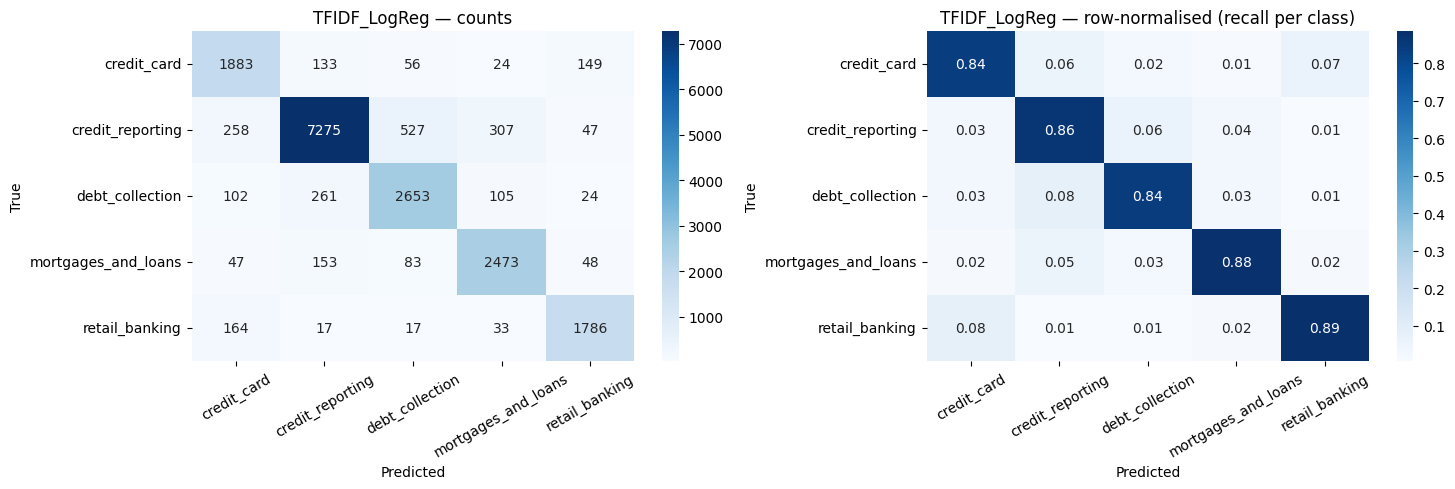

In [6]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

t0 = time.time()
tfidf = TfidfVectorizer(max_features=100_000, ngram_range=(1, 2), sublinear_tf=True, min_df=2)
Xtr_tfidf = tfidf.fit_transform(train_text)          # fit on TRAIN only
Xte_tfidf = tfidf.transform(test_text)

lr = LogisticRegression(max_iter=1000, class_weight='balanced', C=5.0)
lr.fit(Xtr_tfidf, y_train)
print(f'Trained in {time.time()-t0:.0f}s')

res_baseline = evaluate_model('TFIDF_LogReg', y_test, lr.predict(Xte_tfidf))

## 3.4 SimpleRNN from scratch
Architecture: `Embedding → SimpleRNN → Dropout → Dense(softmax)`

- **Embedding(20000, 128):** each word id becomes a learned 128-d vector.
- **SimpleRNN(64):** reads the 250 word-vectors one by one, keeping a hidden state; the final state summarises the text.
- **Dense(5, softmax):** probabilities for the 5 classes (the max is the "confidence" used in Gradio later).
- **clipnorm=1.0:** SimpleRNN suffers from exploding/vanishing gradients; clipping keeps training stable.
- **EarlyStopping** on validation loss, restoring the best weights → protects from overfitting.
- **class_weight** → handles imbalance.

In [7]:
EMB_DIM, UNITS = 128, 64

def build_simplernn():
    m = keras.Sequential([
        layers.Input(shape=(MAX_LEN,)),
        layers.Embedding(VOCAB_SIZE, EMB_DIM),
        layers.SimpleRNN(UNITS),
        layers.Dropout(0.3),
        layers.Dense(len(class_names), activation='softmax'),
    ], name='simplernn')
    m.compile(optimizer=keras.optimizers.Adam(1e-3, clipnorm=1.0),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return m

simplernn = build_simplernn()
simplernn.summary()

Model: "simplernn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 128)       │     2,560,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,572,677 (9.81 MB)

 Trainable params: 2,572,677 (9.81 MB)

 Non-trainable params: 0 (0.00 B)

In [8]:
callbacks = [
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=1, min_lr=1e-5),
]
t0 = time.time()
hist = simplernn.fit(X_train, y_train, validation_data=(X_val, y_val),
                     epochs=2 if QUICK else 15, batch_size=128,
                     class_weight=class_weight, callbacks=callbacks, verbose=2)
train_time = time.time() - t0
print(f'Training time: {train_time/60:.1f} min')

Epoch 1/15
680/680 - 25s - 37ms/step - accuracy: 0.6587 - loss: 0.9003 - val_accuracy: 0.7824 - val_loss: 0.6778 - learning_rate: 0.0010
Epoch 2/15
680/680 - 16s - 24ms/step - accuracy: 0.7818 - loss: 0.6631 - val_accuracy: 0.7778 - val_loss: 0.6991 - learning_rate: 0.0010
Epoch 3/15
680/680 - 16s - 24ms/step - accuracy: 0.8183 - loss: 0.5439 - val_accuracy: 0.7944 - val_loss: 0.6553 - learning_rate: 5.0000e-04
Epoch 4/15
680/680 - 16s - 24ms/step - accuracy: 0.8355 - loss: 0.4831 - val_accuracy: 0.8133 - val_loss: 0.5870 - learning_rate: 5.0000e-04
Epoch 5/15
680/680 - 16s - 24ms/step - accuracy: 0.8537 - loss: 0.4251 - val_accuracy: 0.8054 - val_loss: 0.6066 - learning_rate: 5.0000e-04
Epoch 6/15
680/680 - 16s - 24ms/step - accuracy: 0.8752 - loss: 0.3495 - val_accuracy: 0.8155 - val_loss: 0.5989 - learning_rate: 2.5000e-04
Epoch 7/15
680/680 - 16s - 24ms/step - accuracy: 0.8928 - loss: 0.2974 - val_accuracy: 0.8173 - val_loss: 0.5976 - learning_rate: 1.2500e-04
Training time: 2.1 mi

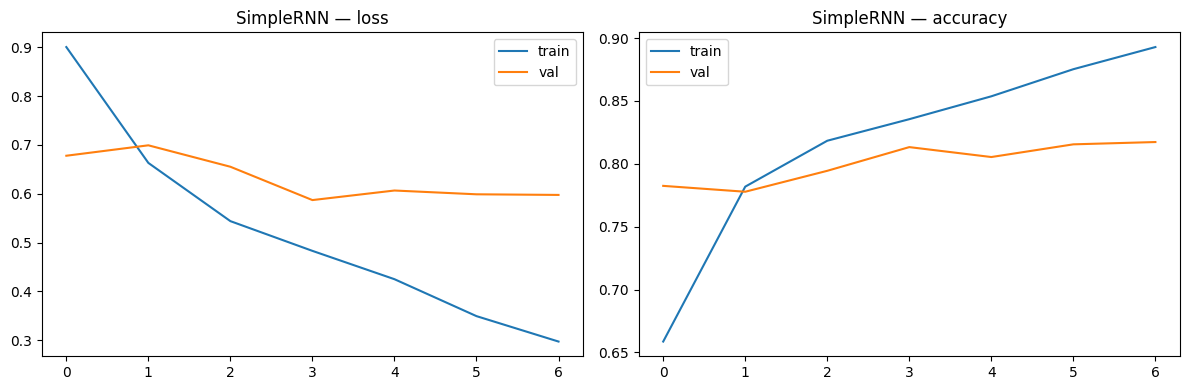

In [9]:
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    ax[0].plot(h.history['loss'], label='train'); ax[0].plot(h.history['val_loss'], label='val'); ax[0].set_title(f'{title} — loss'); ax[0].legend()
    ax[1].plot(h.history['accuracy'], label='train'); ax[1].plot(h.history['val_accuracy'], label='val'); ax[1].set_title(f'{title} — accuracy'); ax[1].legend()
    plt.tight_layout(); plt.show()

plot_history(hist, 'SimpleRNN')

## 3.5 Evaluate SimpleRNN on the test set

===== SimpleRNN =====
Accuracy 0.8143 | Macro-Precision 0.7874 | Macro-Recall 0.8076 | Macro-F1 0.7955

                     precision    recall  f1-score   support

        credit_card      0.720     0.770     0.744      2245
   credit_reporting      0.882     0.842     0.862      8414
    debt_collection      0.779     0.686     0.730      3145
mortgages_and_loans      0.755     0.876     0.811      2804
     retail_banking      0.800     0.864     0.831      2017

           accuracy                          0.814     18625
          macro avg      0.787     0.808     0.796     18625
       weighted avg      0.817     0.814     0.814     18625



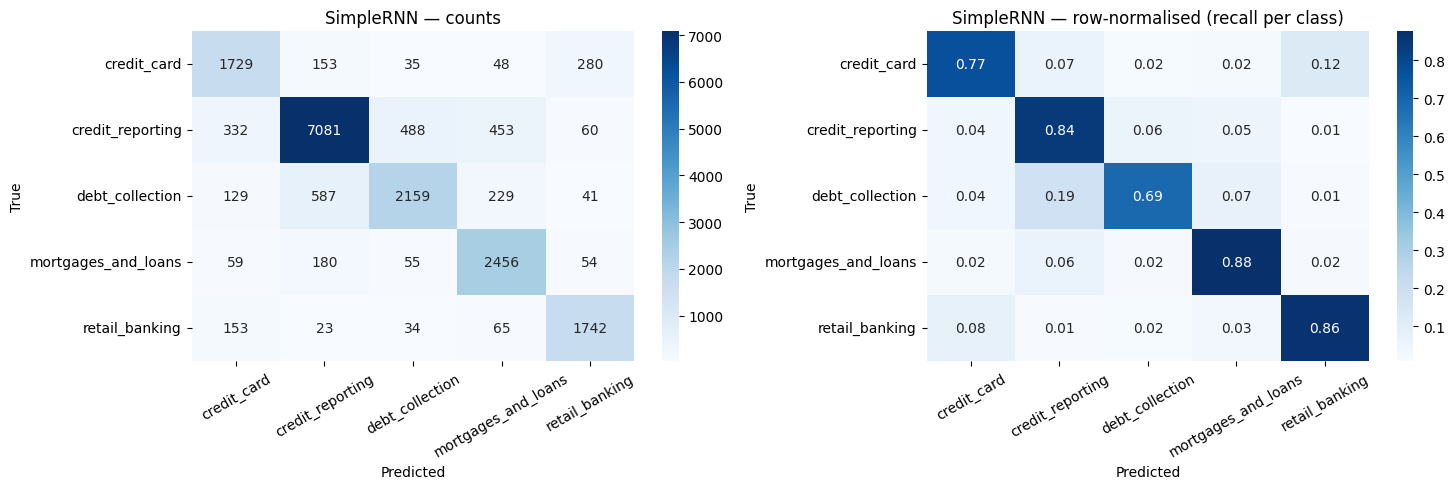

In [10]:
probs = simplernn.predict(X_test, batch_size=256, verbose=0)
res_rnn = evaluate_model('SimpleRNN', y_test, probs.argmax(1))
res_rnn['train_minutes'] = train_time / 60
json.dump(res_rnn, open('results/SimpleRNN.json', 'w'))
simplernn.save('models/simplernn.keras')

## 3.6 Quick comparison so far

In [11]:
rows = [{'model': r['model'], 'accuracy': r['accuracy'], 'macro_F1': r['macro_f1']} for r in [res_baseline, res_rnn]]
pd.DataFrame(rows).round(4)

,model,accuracy,macro_F1
0,TFIDF_LogReg,0.8628,0.8507
1,SimpleRNN,0.8143,0.7955
